In [1]:

# BeeSafe AI | 01 - Dataset Exploration
# Step 1: Imports and project configuration

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem, rdBase
from rdkit.Chem import Descriptors, rdMolDescriptors

PROJECT_ROOT = Path(
    r"E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI"
)

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "dataset_final.csv"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("BeeSafe AI — Dataset Exploration")
print("-" * 45)
print("Project folder exists:", PROJECT_ROOT.exists())
print("Dataset exists:", DATA_PATH.exists())
print("RDKit version:", rdBase.rdkitVersion)
print("Report folder:", REPORT_DIR)
print("Figure folder:", FIGURE_DIR)


BeeSafe AI — Dataset Exploration
---------------------------------------------
Project folder exists: True
Dataset exists: True
RDKit version: 2026.09.1
Report folder: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports
Figure folder: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\figures


In [2]:

# Step 2: Load ApisTox without modifying the original CSV

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Check that dataset_final.csv is inside data/raw."
    )

df_raw = pd.read_csv(DATA_PATH)

# Keep a working copy for exploration
df = df_raw.copy()

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 1035
Number of columns: 13


,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1


In [3]:

# Step 3: Understand the dataset structure

print("COLUMN NAMES")
for column in df.columns:
    print("-", column)

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nFIRST FIVE RECORDS")
display(df.head())

print("\nRANDOM FIVE RECORDS")
display(df.sample(min(5, len(df)), random_state=42))


COLUMN NAMES
- name
- CID
- CAS
- SMILES
- source
- year
- toxicity_type
- herbicide
- fungicide
- insecticide
- other_agrochemical
- label
- ppdb_level

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.DataFrame'>
RangeIndex: 1035 entries, 0 to 1034
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   name                1035 non-null   str  
 1   CID                 1035 non-null   int64
 2   CAS                 1035 non-null   str  
 3   SMILES              1035 non-null   str  
 4   source              1035 non-null   str  
 5   year                1035 non-null   int64
 6   toxicity_type       1035 non-null   str  
 7   herbicide           1035 non-null   int64
 8   fungicide           1035 non-null   int64
 9   insecticide         1035 non-null   int64
 10  other_agrochemical  1035 non-null   int64
 11  label               1035 non-null   int64
 12  ppdb_level          1035 non-null   int64
dtypes: int64(

,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1



RANDOM FIVE RECORDS


,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
294,6-Chloro-3-pyridinecarboxylic acid,79222,5326-23-8,O=C(O)c1ccc(Cl)nc1,ECOTOX,1961,Contact,0,0,0,1,0,1
453,2-Methyl-2-(methylsulfinyl)propanal O-[(methyl...,9568700,1646-87-3,CNC(=O)ON=CC(C)(C)S(C)=O,ECOTOX,1973,Other,0,0,0,1,1,2
638,"(4R,5R)-rel-5-(4-Chlorophenyl)-N-cyclohexyl-4-...",13218777,78587-05-0,CC1C(c2ccc(Cl)cc2)SC(=O)N1C(=O)NC1CCCCC1,ECOTOX,1988,Oral,0,0,0,1,0,1
139,Rotenone (Ref: ENT 133),6758,83-79-4,C=C(C)C1Cc2c(ccc3c2OC2COc4cc(OC)c(OC)cc4C2C3=O)O1,BPDB,1929,Contact,0,0,1,0,1,2
539,Dienochlor (Ref: SAN 804),16686,2227-17-0,ClC1=C(Cl)C(Cl)(C2(Cl)C(Cl)=C(Cl)C(Cl)=C2Cl)C(...,PPDB,1979,Contact,0,0,1,0,0,1


In [4]:

# Step 4: Check missing values and duplicate records

missing_values = df.isnull().sum()

quality_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2),
    "Unique Values": df.nunique(dropna=True)
})

print("DATA QUALITY REPORT")
display(quality_report)

print("Dataset shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())
print("Rows with repeated CID:", df["CID"].duplicated().sum())
print("Number of distinct CIDs:", df["CID"].nunique())
print("Number of distinct SMILES:", df["SMILES"].nunique())


DATA QUALITY REPORT


,Data Type,Missing Values,Missing Percentage,Unique Values
name,str,0,0.0,1035
CID,int64,0,0.0,1030
CAS,str,0,0.0,1035
SMILES,str,0,0.0,1035
source,str,0,0.0,3
year,int64,0,0.0,158
toxicity_type,str,0,0.0,3
herbicide,int64,0,0.0,2
fungicide,int64,0,0.0,2
insecticide,int64,0,0.0,2


Dataset shape: (1035, 13)
Exact duplicate rows: 0
Rows with repeated CID: 5
Number of distinct CIDs: 1030
Number of distinct SMILES: 1035


In [5]:

# Step 5: Primary target distribution

print("PRIMARY TARGET: label")
print("Unique target values:", sorted(df["label"].dropna().unique()))

label_counts = df["label"].value_counts(dropna=False).sort_index()

label_percentages = (
    df["label"].value_counts(normalize=True, dropna=False)
    .sort_index()
    .mul(100)
    .round(2)
)

label_summary = pd.DataFrame({
    "Count": label_counts,
    "Percentage": label_percentages
})

display(label_summary)

print("\nInterpretation:")
print("label = 0: dataset-defined non-toxic class")
print("label = 1: dataset-defined toxic class")


PRIMARY TARGET: label
Unique target values: [np.int64(0), np.int64(1)]


,Count,Percentage
label,,
0,739,71.4
1,296,28.6



Interpretation:
label = 0: dataset-defined non-toxic class
label = 1: dataset-defined toxic class


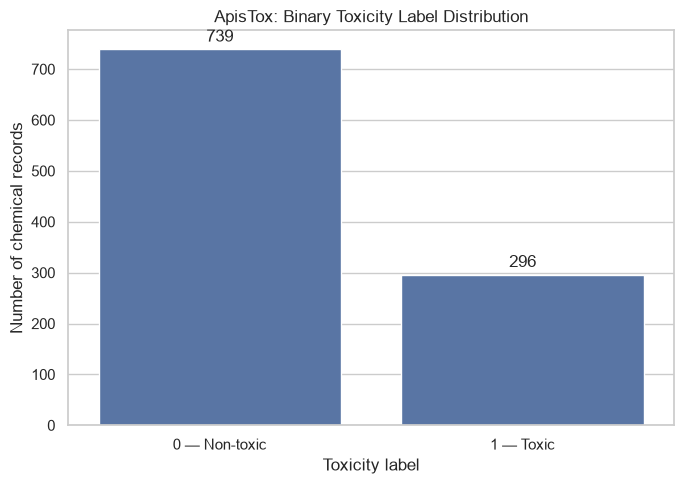

In [6]:

# Step 6: Plot the primary target distribution

plot_data = df.dropna(subset=["label"]).copy()

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=plot_data,
    x="label",
    order=sorted(plot_data["label"].unique())
)

ax.set_title("ApisTox: Binary Toxicity Label Distribution")
ax.set_xlabel("Toxicity label")
ax.set_ylabel("Number of chemical records")
ax.set_xticks([0, 1])
ax.set_xticklabels(["0 — Non-toxic", "1 — Toxic"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "01_label_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


PPDB LEVEL DISTRIBUTION


,Count,Percentage
ppdb_level,,
0,177,17.10
1,687,66.38
2,171,16.52


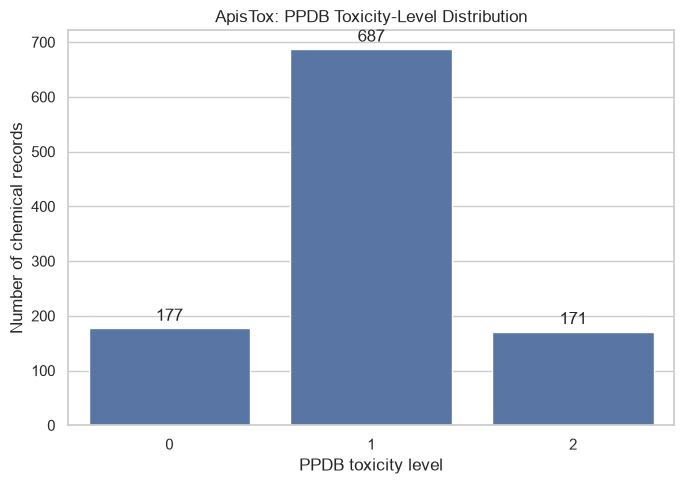

In [7]:

# Step 7: Three-level toxicity target

ppdb_counts = df["ppdb_level"].value_counts(
    dropna=False
).sort_index()

ppdb_percentages = (
    df["ppdb_level"]
    .value_counts(normalize=True, dropna=False)
    .sort_index()
    .mul(100)
    .round(2)
)

ppdb_summary = pd.DataFrame({
    "Count": ppdb_counts,
    "Percentage": ppdb_percentages
})

print("PPDB LEVEL DISTRIBUTION")
display(ppdb_summary)

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df.dropna(subset=["ppdb_level"]),
    x="ppdb_level",
    order=sorted(df["ppdb_level"].dropna().unique())
)

ax.set_title("ApisTox: PPDB Toxicity-Level Distribution")
ax.set_xlabel("PPDB toxicity level")
ax.set_ylabel("Number of chemical records")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "02_ppdb_level_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [8]:

# Step 8: Categorical feature exploration

categorical_columns = ["source", "toxicity_type"]

for column in categorical_columns:
    print(f"\nDistribution of {column}")
    
    counts = df[column].value_counts(dropna=False)
    display(counts.to_frame("Count"))

    percentages = (
        df[column]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )

    display(percentages.to_frame("Percentage"))

# Explore agricultural-use indicators
agro_columns = [
    "herbicide",
    "fungicide",
    "insecticide",
    "other_agrochemical"
]

print("\nAGROCHEMICAL INDICATORS")

for column in agro_columns:
    print(f"\n{column}")
    display(
        df[column]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("Count")
    )



Distribution of source


,Count
source,
PPDB,510
ECOTOX,441
BPDB,84


,Percentage
source,
PPDB,49.28
ECOTOX,42.61
BPDB,8.12



Distribution of toxicity_type


,Count
toxicity_type,
Contact,625
Oral,291
Other,119


...

,Count
fungicide,
0,838
1,197



insecticide


,Count
insecticide,
0,808
1,227



other_agrochemical


,Count
other_agrochemical,
0,819
1,216


In [9]:

# Step 9: Inspect repeated PubChem CIDs

repeated_cids = df[
    df["CID"].duplicated(keep=False)
].sort_values("CID")

print("Rows involved in repeated CIDs:", len(repeated_cids))
print("Distinct repeated CIDs:", repeated_cids["CID"].nunique())

display(
    repeated_cids[
        [
            "name", "CID", "CAS", "SMILES", "source",
            "toxicity_type", "label", "ppdb_level"
        ]
    ]
)

print("\nRepeated SMILES strings:")

repeated_smiles = df[
    df["SMILES"].duplicated(keep=False)
].sort_values("SMILES")

print("Rows involved in repeated SMILES:", len(repeated_smiles))

display(
    repeated_smiles[
        [
            "name", "CID", "CAS", "SMILES",
            "source", "label", "ppdb_level"
        ]
    ].head(30)
)


Rows involved in repeated CIDs: 10
Distinct repeated CIDs: 5


,name,CID,CAS,SMILES,source,toxicity_type,label,ppdb_level
290,Chlormequat,13836,7003-89-6,C[N+](C)(C)CCCl,PPDB,Contact,0,1
295,"2-Chloro-N,N,N-trimethylethanaminium chloride ...",13836,999-81-5,C[N+](C)(C)CCCl.[Cl-],ECOTOX,Contact,0,1
416,N-(2-Methylcyclohexyl)-N'-phenylurea,16116,1982-49-6,CC1CCCCC1NC(=O)Nc1ccccc1,ECOTOX,Contact,0,0
413,Silthiofam (Ref: MON 65500),16116,175217-20-6,C=CCNC(=O)c1c([Si](C)(C)C)sc(C)c1C,PPDB,Contact,0,1
670,Diclomezine (Ref: F-850),93341,62865-36-5,Cc1c(Cl)cc(-c2ccc(=O)[nH]n2)cc1Cl,PPDB,Contact,0,1
672,Diflumetorim (Ref: UBF 002),93341,130339-07-0,CCC(Nc1ncnc(C)c1Cl)c1ccc(OC(F)F)cc1,PPDB,Oral,1,1
328,Zineb (Ref: ENT 14874),5284484,12122-67-7,S=C([S-])NCCNC(=S)[S-].[Zn+2],PPDB,Contact,1,1
323,Metiram (Ref: BAS 222F),5284484,9006-42-2,S=C([S-])NCCNC(=S)S.S=C([S-])NCCNC(=S)S.[NH2-]...,PPDB,Contact,0,1
824,Metominostrobin (Ref: SSF 126),5483872,133408-50-1,CNC(=O)C(=NOC)c1ccccc1Oc1ccccc1,PPDB,Contact,0,1
832,Phthalide (Ref: BAY 96610),5483872,27355-22-2,O=C1OCc2c(Cl)c(Cl)c(Cl)c(Cl)c21,PPDB,Contact,0,0



Repeated SMILES strings:
Rows involved in repeated SMILES: 0


,name,CID,CAS,SMILES,source,label,ppdb_level


In [10]:

# Step 10: Check whether SMILES strings can be parsed by RDKit

def validate_smiles(smiles):
    if not isinstance(smiles, str) or not smiles.strip():
        return False

    try:
        return Chem.MolFromSmiles(smiles) is not None
    except Exception:
        return False


smiles_validity = df["SMILES"].apply(validate_smiles)

smiles_summary = pd.DataFrame({
    "Status": ["Valid", "Invalid or empty"],
    "Count": [
        int(smiles_validity.sum()),
        int((~smiles_validity).sum())
    ]
})

print("SMILES VALIDATION SUMMARY")
display(smiles_summary)

print("Valid percentage:",
      round(smiles_validity.mean() * 100, 2), "%")

invalid_smiles = df.loc[
    ~smiles_validity,
    ["name", "CID", "CAS", "SMILES", "label"]
]

print("\nInvalid or empty SMILES records:")
display(invalid_smiles)


SMILES VALIDATION SUMMARY


,Status,Count
0,Valid,1035
1,Invalid or empty,0


Valid percentage: 100.0 %

Invalid or empty SMILES records:


,name,CID,CAS,SMILES,label


In [11]:

# Step 11: Calculate descriptors for valid SMILES only

valid_indices = df.index[smiles_validity]

df_chem = df.loc[valid_indices].copy()

molecules = [
    Chem.MolFromSmiles(smiles)
    for smiles in df_chem["SMILES"]
]

descriptor_records = []

for mol in molecules:
    descriptor_records.append({
        "MolecularWeight": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "RingCount": rdMolDescriptors.CalcNumRings(mol)
    })

descriptor_df = pd.DataFrame(
    descriptor_records,
    index=df_chem.index
)

df_chem = pd.concat([df_chem, descriptor_df], axis=1)

print("Descriptor calculation complete.")
print("Valid chemical records:", len(df_chem))

display(
    df_chem[
        [
            "name", "SMILES", "label",
            "MolecularWeight", "LogP", "TPSA",
            "HBD", "HBA", "RingCount"
        ]
    ].head()
)


Descriptor calculation complete.
Valid chemical records: 1035


,name,SMILES,label,MolecularWeight,LogP,TPSA,HBD,HBA,RingCount
0,Ethanedioic acid,O=C(O)C(=O)O,0,90.034,-0.84440,74.60,2,2,0
1,Para-cymene,Cc1ccc(C(C)C)cc1,0,134.222,3.11842,0.00,0,0,1
2,Kieselguhr,O=[Si]=O,0,60.084,-0.61840,34.14,0,2,0
3,Benzoic acid,O=C(O)c1ccccc1,0,122.123,1.38480,37.30,1,1,1
4,Tetradifon (Ref: ENT 23737),O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,1,356.057,5.13300,34.14,0,2,2


In [12]:

# Step 12: Descriptive statistics for molecular features

descriptor_columns = [
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RingCount"
]

print("MOLECULAR DESCRIPTOR SUMMARY")

display(
    df_chem[descriptor_columns]
    .describe()
    .T
    .round(3)
)

print("\nDescriptor summaries by binary toxicity label")

display(
    df_chem.groupby("label")[descriptor_columns]
    .agg(["mean", "median", "std"])
    .round(3)
)


MOLECULAR DESCRIPTOR SUMMARY


,count,mean,std,min,25%,50%,75%,max
MolecularWeight,1035.0,319.782,151.767,32.067,229.715,310.297,379.960,1732.153
LogP,1035.0,2.496,3.096,-20.533,1.426,2.876,4.190,19.786
TPSA,1035.0,67.046,60.569,0.000,36.920,55.840,80.275,896.660
HBD,1035.0,0.933,1.880,0.000,0.000,0.000,1.000,30.000
HBA,1035.0,4.214,3.285,0.000,2.000,4.000,5.000,47.000
RingCount,1035.0,1.724,1.438,0.000,1.000,2.000,2.000,15.000



Descriptor summaries by binary toxicity label


MolecularWeight                     LogP                  TPSA                   HBD                  HBA  \
                 mean   median      std   mean median    std    mean median     std   mean median    std   mean   
label                                                                                                             
0             309.515  302.201  142.278  2.160  2.712  3.184  70.399  57.65  65.913  1.068    1.0  2.093  4.103   
1             345.415  322.497  170.786  3.335  3.528  2.693  58.677  53.47  43.491  0.598    0.0  1.131  4.490   

                    RingCount                
      median    std      mean median    std  
label                                        
0        4.0  3.367     1.720    2.0  1.323  
1        4.0  3.059     1.733    1.5  1.695

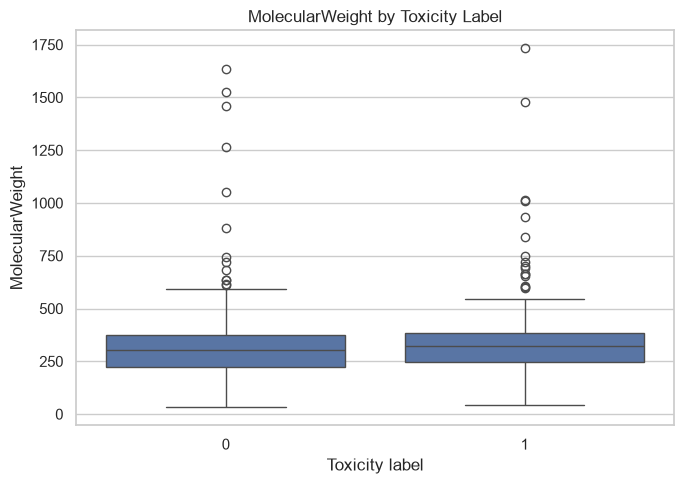

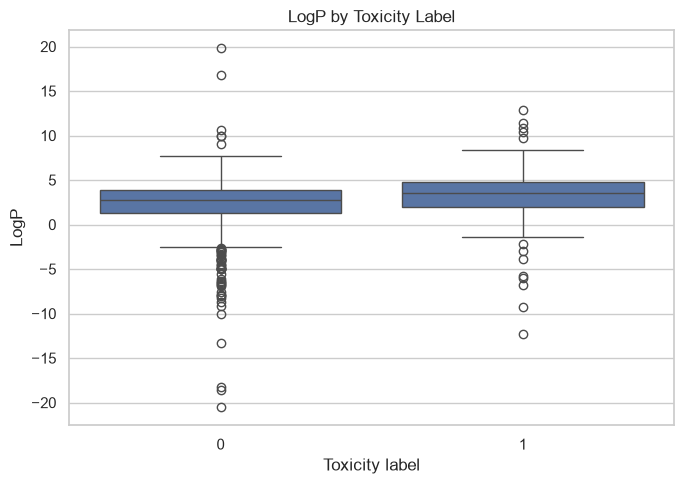

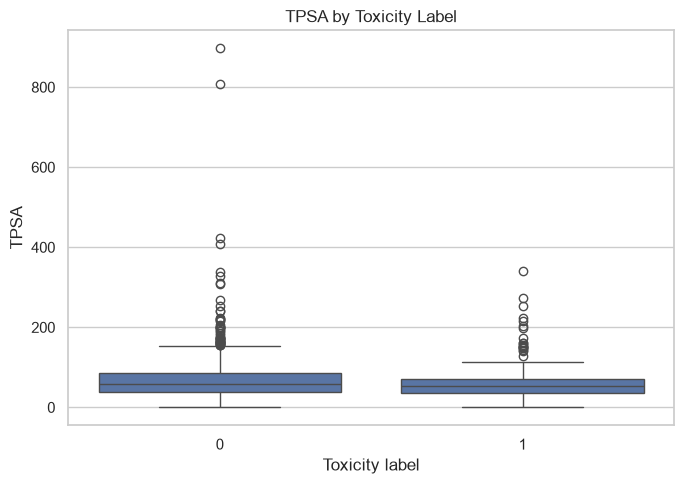

In [13]:

# Step 13: Compare selected descriptors between label classes

features_to_plot = [
    "MolecularWeight",
    "LogP",
    "TPSA"
]

for feature in features_to_plot:
    plt.figure(figsize=(7, 5))

    ax = sns.boxplot(
        data=df_chem.dropna(subset=["label", feature]),
        x="label",
        y=feature
    )

    ax.set_title(f"{feature} by Toxicity Label")
    ax.set_xlabel("Toxicity label")
    ax.set_ylabel(feature)

    plt.tight_layout()

    filename = f"descriptor_{feature.lower()}.png"

    plt.savefig(
        FIGURE_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


In [14]:

# Step 14: Save reports and derived exploration data locally

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save data-quality and target summaries
quality_report.to_csv(
    REPORT_DIR / "dataset_quality_summary.csv"
)

label_summary.to_csv(
    REPORT_DIR / "label_distribution.csv"
)

ppdb_summary.to_csv(
    REPORT_DIR / "ppdb_level_distribution.csv"
)

# Save the SMILES validation report
smiles_audit = df[
    ["name", "CID", "CAS", "SMILES", "label"]
].copy()

smiles_audit["smiles_valid"] = smiles_validity

smiles_audit.to_csv(
    REPORT_DIR / "smiles_validation_report.csv",
    index=False
)

# Save the derived molecular descriptors
df_chem.to_csv(
    PROCESSED_DIR / "chemical_descriptors_exploration.csv",
    index=False
)

print("Reports saved to:", REPORT_DIR)
print("Derived descriptor data saved to:", PROCESSED_DIR)
print("\nGenerated files:")

for path in sorted(REPORT_DIR.iterdir()):
    if path.is_file():
        print("-", path.name)

print("\nGenerated figures:")

for path in sorted(FIGURE_DIR.iterdir()):
    if path.is_file():
        print("-", path.name)


Reports saved to: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports
Derived descriptor data saved to: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\processed

Generated files:
- dataset_quality_summary.csv
- label_distribution.csv
- ppdb_level_distribution.csv
- smiles_validation_report.csv

Generated figures:
- 01_label_distribution.png
- 02_ppdb_level_distribution.png
- descriptor_logp.png
- descriptor_molecularweight.png
- descriptor_tpsa.png


In [15]:

# Step 15: Final summary of dataset exploration

print("=" * 55)
print("BEESAFE AI — DATASET EXPLORATION SUMMARY")
print("=" * 55)

print(f"Original records: {len(df_raw)}")
print(f"Original columns: {len(df_raw.columns)}")

print(f"Missing cells: {int(df_raw.isnull().sum().sum())}")
print(f"Exact duplicate rows: {int(df_raw.duplicated().sum())}")

print(
    "Repeated CID occurrences:",
    int(df_raw["CID"].duplicated().sum())
)

print(
    "Distinct repeated CIDs:",
    int(df_raw.loc[
        df_raw["CID"].duplicated(keep=False), "CID"
    ].nunique())
)

print(f"Valid SMILES: {int(smiles_validity.sum())}")
print(f"Invalid or empty SMILES: {int((~smiles_validity).sum())}")

print("\nBinary toxicity distribution:")
display(label_summary)

print("\nPPDB level distribution:")
display(ppdb_summary)

print("\nExploration outputs saved successfully.")
print("Next stage: review identifier and structure issues.")


BEESAFE AI — DATASET EXPLORATION SUMMARY
Original records: 1035
Original columns: 13
Missing cells: 0
Exact duplicate rows: 0
Repeated CID occurrences: 5
Distinct repeated CIDs: 5
Valid SMILES: 1035
Invalid or empty SMILES: 0

Binary toxicity distribution:


,Count,Percentage
label,,
0,739,71.4
1,296,28.6



PPDB level distribution:


,Count,Percentage
ppdb_level,,
0,177,17.10
1,687,66.38
2,171,16.52



Exploration outputs saved successfully.
Next stage: review identifier and structure issues.
